# Physics-Informed Optical Science Automation

A learning project that teaches Python flow control, symbolic math,
Fourier analysis, binary data, differentiable models and
optical-imaging ideas through seven small experiments you can run one
at a time.

## Scope and boundaries

- **All data is simulated** inside this notebook. No private, personal,
  medical or identity data is used or needed.
- **Stage 6 is a visualization exercise.** The "brain map" is a made-up
  array. It cannot diagnose anyone and does not read minds.
- **This is not a clinical or laboratory instrument.** The models are
  teaching simplifications.
- **The Jalali Lab connection is conceptual.** It refers only to
  publicly described scientific ideas (photonic time-stretch,
  RF-tagged fluorescence, physics-inspired image processing). No
  proprietary equipment or lab data is involved.

## The seven stages

| Stage | Command | Physics / engineering idea | Python idea practised |
|---|---|---|---|
| 0 | — | setup, safe file saving | variables and types, file output |
| 1 | `simulate` | $s(t) = A\cos(2\pi f t + \phi) + n(t)$ | functions, arrays |
| 2 | `fft` | Fourier transform, Nyquist, leakage | `for` loops, lists |
| 3 | `binary` | 8-bit ADC, quantization error | `if/elif/else`, `while`, exceptions |
| 4 | `symbolic` | derivatives, integrals, limits in SymPy | functions that refuse bad input |
| 5 | `fit` | differentiable Gaussian spot in PyTorch | `while` loop with a stopping rule, classes |
| 6 | `brain_map` | a labelled data cube with uncertainty | dictionaries, multi-dimensional arrays |
| 7 | `classify` | interpretable features, decision tree | file input/output, pandas |
| — | controller | automation pipeline, phone mode | command dispatch, error handling |

## How to use it

Run the cells top to bottom once. After that, any single experiment can
be re-run from the controller near the end, for example
`main(["fft", "--phone"])`. **Phone mode** shrinks each experiment and
runs only one at a time.

Each stage has the same layout: the idea in plain English, one code
cell with a worked example, then how to say it in engineering language,
and three exercises with solutions.

# Stage 0 — Setup and safe file saving

Every experiment saves a plot and a small numerical summary into a
local `results/` folder. The saving rule is:

- **No filename given** → the next free numbered name is used
  (`fft_001.png`, `fft_002.png`, …), so nothing is ever overwritten.
- **Explicit filename given** → that exact file is written. Choosing the
  name is how you say "yes, replace it".

This cell also shows Python's basic value types.

In [1]:
# Stage 0 -- setup. Every later cell needs this one.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.figure import Figure


def show_variable_types() -> None:
    '''Print the four basic Python value types used throughout the project.'''
    sample_rate_hz: float = 100e6       # float: a number with a decimal point
    n_samples: int = 200                # int: a whole number
    sensor_name: str = "photodetector"  # str: text
    is_simulated: bool = True           # bool: True or False
    for name, value in [("sample_rate_hz", sample_rate_hz), ("n_samples", n_samples),
                        ("sensor_name", sensor_name), ("is_simulated", is_simulated)]:
        print(f"{name:15s} = {value!r:16}  type: {type(value).__name__}")


def resolve_output_path(results_dir: Path, stem: str, suffix: str, filename: str) -> Path:
    '''Decide where to save. An empty filename means "pick the next free numbered name".'''
    results_dir.mkdir(parents=True, exist_ok=True)
    if filename != "":
        return results_dir / filename          # explicit name: the caller chose it
    number = 1
    while (results_dir / f"{stem}_{number:03d}{suffix}").exists():
        number += 1                            # keep counting until the name is free
    return results_dir / f"{stem}_{number:03d}{suffix}"


def save_outputs(fig: Figure, summary: dict[str, float], results_dir: Path,
                 stem: str, filename: str) -> Path:
    '''Save the plot as PNG and the numbers as a JSON file with the same name.'''
    plot_path = resolve_output_path(results_dir, stem, ".png", filename)
    fig.savefig(plot_path, dpi=110, bbox_inches="tight")
    plot_path.with_suffix(".json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return plot_path


def finish_figure(fig: Figure, show: bool) -> None:
    '''Display the figure if asked, then close it so memory use stays small.'''
    if show:
        plt.show()
    plt.close(fig)


def print_summary(summary: dict[str, float]) -> None:
    '''Print a summary dictionary one line per entry.'''
    for key, value in summary.items():
        print(f"  {key:32s} {value:.6g}")


show_variable_types()

sample_rate_hz  = 100000000.0       type: float
n_samples       = 200               type: int
sensor_name     = 'photodetector'   type: str
is_simulated    = True              type: bool


# Stage 1 — Optical signal simulation

$$s(t) = A\cos(2\pi f t + \phi) + n(t)$$

**In plain English.** A photodetector turns light into a voltage. If the
light's brightness is wiggling at a steady rate, the voltage is a cosine
wave plus random noise.

| Symbol | Meaning | Unit |
|---|---|---|
| $A$ | amplitude: how big the wiggle is | V |
| $f$ | frequency: wiggles per second | Hz |
| $\phi$ | phase: where in its cycle the wave starts | rad |
| $n(t)$ | noise: random error added to every sample | V |
| $f_s$ | sampling rate: how many readings per second | Hz |

A computer cannot store a continuous curve, so it stores **samples**
taken every $1/f_s$ seconds. The **signal-to-noise ratio** compares
signal power $A^2/2$ with noise power $\sigma^2$:
$\mathrm{SNR} = 10\log_{10}\!\big(\tfrac{A^2/2}{\sigma^2}\big)$ dB.

**Worked example.** $A = 1.0$ V, $f = 5$ MHz, $\phi = \pi/4$,
$\sigma = 0.05$ V, sampled at $f_s = 100$ MHz for 2 µs.

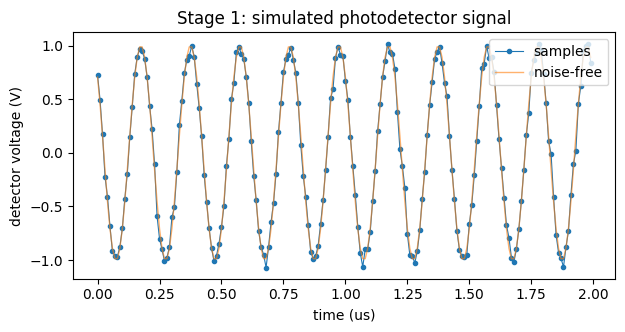

  n_samples                        200
  snr_db                           23.0103
  rms_measured_v                   0.703995
  rms_expected_v                   0.708872


In [2]:
# Stage 1 -- simulate a noisy cosine. Needs the Stage 0 cell.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def make_time_axis(duration_s: float, sample_rate_hz: float) -> np.ndarray:
    '''Sample times in seconds: 0, 1/fs, 2/fs, ...'''
    n_samples = int(round(duration_s * sample_rate_hz))
    return np.arange(n_samples) / sample_rate_hz


def simulate_signal(time_s: np.ndarray, amplitude_v: float, frequency_hz: float,
                    phase_rad: float, noise_std_v: float, seed: int) -> np.ndarray:
    '''s(t) = A cos(2 pi f t + phi) + n(t), with Gaussian noise of standard deviation sigma.'''
    rng = np.random.default_rng(seed)             # the seed makes the "random" noise repeatable
    clean_v = amplitude_v * np.cos(2 * np.pi * frequency_hz * time_s + phase_rad)
    return clean_v + rng.normal(0.0, noise_std_v, size=time_s.shape)


def snr_db(amplitude_v: float, noise_std_v: float) -> float:
    '''Signal power A^2/2 over noise power sigma^2, in decibels.'''
    return float(10 * np.log10((amplitude_v**2 / 2) / noise_std_v**2))


def run_simulate(results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Simulate, plot and summarise one noisy cosine.'''
    amplitude_v, frequency_hz, phase_rad, noise_std_v = 1.0, 5e6, np.pi / 4, 0.05
    sample_rate_hz = 100e6
    duration_s = 1e-6 if phone_mode else 2e-6     # phone mode: half as many samples
    time_s = make_time_axis(duration_s, sample_rate_hz)
    signal_v = simulate_signal(time_s, amplitude_v, frequency_hz, phase_rad, noise_std_v, seed=1)

    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.plot(time_s * 1e6, signal_v, ".-", lw=0.8, label="samples")
    ax.plot(time_s * 1e6, amplitude_v * np.cos(2 * np.pi * frequency_hz * time_s + phase_rad),
            lw=1, alpha=0.6, label="noise-free")
    ax.set_xlabel("time (us)"); ax.set_ylabel("detector voltage (V)")
    ax.set_title("Stage 1: simulated photodetector signal"); ax.legend(loc="upper right")

    summary = {
        "n_samples": float(time_s.size),
        "snr_db": snr_db(amplitude_v, noise_std_v),
        "rms_measured_v": float(np.sqrt(np.mean(signal_v**2))),
        "rms_expected_v": float(np.sqrt(amplitude_v**2 / 2 + noise_std_v**2)),
    }
    save_outputs(fig, summary, results_dir, "simulate", filename)
    finish_figure(fig, show)
    return summary


stage1 = run_simulate(results_dir=Path("results"), phone_mode=False,
                      filename="stage1_signal.png", show=True)
print_summary(stage1)
assert abs(stage1["rms_measured_v"] - stage1["rms_expected_v"]) < 0.02

**In engineering language**

- *We measured* (here: simulated) the detector voltage in volts at 200
  instants spaced 10 ns apart.
- *We estimated* the RMS voltage by averaging the squared samples,
  assuming the record covers a whole number of cycles.
- *We validated* it against the known answer $\sqrt{A^2/2 + \sigma^2}$;
  they agree to within 0.02 V.

**Exercises**

1. With $f_s = 100$ MHz and a 2 µs record, how many samples are there?
2. If the noise standard deviation doubles, by how many dB does the SNR change?
3. What phase $\phi$ turns the cosine into a sine?

<details><summary>Solutions</summary>

1. $N = f_s \times T = 100\times10^{6} \times 2\times10^{-6} = 200$.
2. Noise power goes up 4×, so SNR drops by $10\log_{10}4 = 6.02$ dB.
3. $\phi = -\pi/2$, because $\cos(\theta - \pi/2) = \sin\theta$.

</details>

# Stage 2 — The Fourier transform

**In plain English.** The Fourier transform answers "which frequencies
are in this signal, and how strong is each one?" The FFT is the fast
algorithm that computes it from samples.

Four numbers control what an FFT can and cannot show:

| Quantity | Formula | Meaning |
|---|---|---|
| Sampling frequency | $f_s$ | readings per second |
| Nyquist frequency | $f_s/2$ | highest frequency that can be represented; anything above it **aliases** to a false lower frequency |
| Resolution | $\Delta f = f_s/N = 1/T$ | spacing of the frequency bins; a longer record gives finer bins |
| Spectral leakage | — | a tone that falls *between* bins smears into its neighbours; a window (Hann) trades a wider peak for much less smearing |

**Worked example: RF-tagged pixels.** Three "pixels" of a sample are
each made to flicker at their own radio frequency (10, 15 and 20 MHz)
with brightness 1.0, 0.4 and 0.7. A *single* detector sees the sum. The
FFT separates them again, because each pixel owns one frequency bin.
This is the idea behind RF-tagged fluorescence imaging.

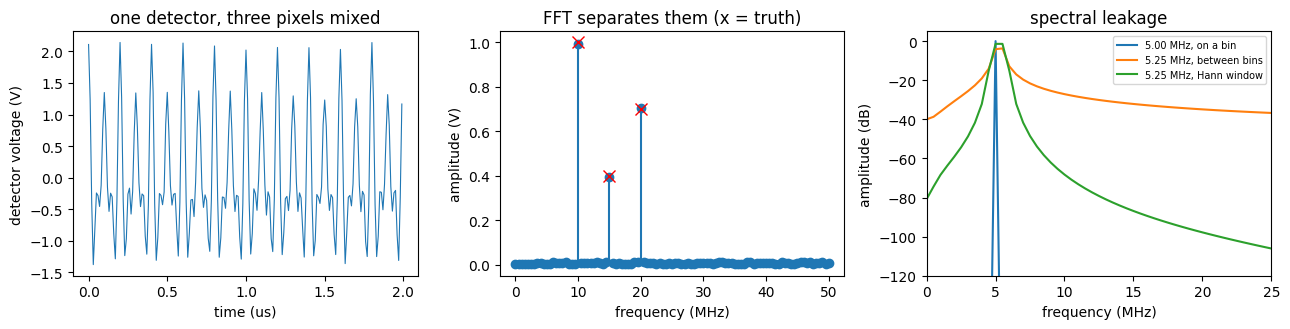

  resolution_hz                    500000
  nyquist_hz                       5e+07
  max_brightness_error             0.00703759
  alias_of_70MHz_hz                3e+07


In [3]:
# Stage 2 -- FFT of a simulated detector signal. Needs the Stage 0 cell.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def amplitude_spectrum(signal_v: np.ndarray, sample_rate_hz: float,
                       use_hann_window: bool) -> tuple[np.ndarray, np.ndarray]:
    '''One-sided amplitude spectrum, scaled so a cosine of amplitude A shows a peak of height A.'''
    n_samples = signal_v.size
    window = np.hanning(n_samples) if use_hann_window else np.ones(n_samples)
    spectrum = np.fft.rfft(signal_v * window)
    freqs_hz = np.fft.rfftfreq(n_samples, d=1 / sample_rate_hz)
    return freqs_hz, 2 * np.abs(spectrum) / window.sum()


def simulate_rf_tagged_pixels(time_s: np.ndarray, tag_frequencies_hz: list[float],
                              brightness: list[float], noise_std_v: float, seed: int) -> np.ndarray:
    '''Sum of cosines: each pixel contributes its brightness at its own tag frequency.'''
    rng = np.random.default_rng(seed)
    signal_v = np.zeros_like(time_s)
    for tag_hz, pixel_brightness in zip(tag_frequencies_hz, brightness):   # one pass per pixel
        signal_v += pixel_brightness * np.cos(2 * np.pi * tag_hz * time_s)
    return signal_v + rng.normal(0.0, noise_std_v, size=time_s.shape)


def read_tagged_brightness(freqs_hz: np.ndarray, amplitude_v: np.ndarray,
                           tag_frequencies_hz: list[float]) -> list[float]:
    '''Read the spectrum height at the bin nearest to each tag frequency.'''
    recovered = []
    for tag_hz in tag_frequencies_hz:
        nearest_bin = int(np.argmin(np.abs(freqs_hz - tag_hz)))
        recovered.append(float(amplitude_v[nearest_bin]))
    return recovered


def alias_frequency(frequency_hz: float, sample_rate_hz: float) -> float:
    '''Where a tone appears after sampling: folded back into the range 0 .. fs/2.'''
    return float(abs(frequency_hz - sample_rate_hz * round(frequency_hz / sample_rate_hz)))


def run_fft(results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Recover three RF-tagged pixel brightnesses with an FFT, and show spectral leakage.'''
    sample_rate_hz = 100e6
    duration_s = 1e-6 if phone_mode else 2e-6
    time_s = np.arange(int(round(duration_s * sample_rate_hz))) / sample_rate_hz
    tag_frequencies_hz, true_brightness = [10e6, 15e6, 20e6], [1.0, 0.4, 0.7]

    signal_v = simulate_rf_tagged_pixels(time_s, tag_frequencies_hz, true_brightness, 0.05, seed=2)
    freqs_hz, amplitude_v = amplitude_spectrum(signal_v, sample_rate_hz, use_hann_window=False)
    recovered = read_tagged_brightness(freqs_hz, amplitude_v, tag_frequencies_hz)
    errors = [abs(r - b) for r, b in zip(recovered, true_brightness)]

    # leakage: a tone exactly on a bin versus one a fraction of a bin off
    on_bin = np.cos(2 * np.pi * 5.00e6 * time_s)
    off_bin = np.cos(2 * np.pi * 5.25e6 * time_s)
    to_db = lambda a: 20 * np.log10(a + 1e-12)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    axes[0].plot(time_s * 1e6, signal_v, lw=0.8)
    axes[0].set_xlabel("time (us)"); axes[0].set_ylabel("detector voltage (V)")
    axes[0].set_title("one detector, three pixels mixed")
    axes[1].stem(freqs_hz / 1e6, amplitude_v, basefmt=" ")
    for tag_hz, pixel_brightness in zip(tag_frequencies_hz, true_brightness):
        axes[1].plot(tag_hz / 1e6, pixel_brightness, "rx", ms=9)
    axes[1].set_xlabel("frequency (MHz)"); axes[1].set_ylabel("amplitude (V)")
    axes[1].set_title("FFT separates them (x = truth)")
    for label, tone, hann in [("5.00 MHz, on a bin", on_bin, False),
                              ("5.25 MHz, between bins", off_bin, False),
                              ("5.25 MHz, Hann window", off_bin, True)]:
        f_hz, a_v = amplitude_spectrum(tone, sample_rate_hz, use_hann_window=hann)
        axes[2].plot(f_hz / 1e6, to_db(a_v), label=label)
    axes[2].set_ylim(-120, 5); axes[2].set_xlim(0, 25)
    axes[2].set_xlabel("frequency (MHz)"); axes[2].set_ylabel("amplitude (dB)")
    axes[2].set_title("spectral leakage"); axes[2].legend(fontsize=7)
    fig.tight_layout()

    summary = {
        "resolution_hz": sample_rate_hz / time_s.size,
        "nyquist_hz": sample_rate_hz / 2,
        "max_brightness_error": float(max(errors)),
        "alias_of_70MHz_hz": alias_frequency(70e6, sample_rate_hz),
    }
    save_outputs(fig, summary, results_dir, "fft", filename)
    finish_figure(fig, show)
    return summary


stage2 = run_fft(results_dir=Path("results"), phone_mode=False, filename="stage2_fft.png", show=True)
print_summary(stage2)
assert stage2["max_brightness_error"] < 0.03

**Reading the leakage panel.** The on-bin tone is a single clean
spike. The same tone moved a quarter of the way to the next bin spreads
energy across the whole spectrum (the slowly falling skirt). The Hann
window makes the main peak a little wider but pushes the skirt far down.

**In engineering language**

- *We measured* a single detector voltage record: 200 samples at 100 MS/s.
- *We estimated* each pixel's brightness as the FFT amplitude at its tag
  frequency, assuming the tags sit exactly on FFT bins and do not overlap.
- *We validated* against the brightness values put into the simulation;
  the largest error is below 0.03.

**Exercises**

1. For $f_s = 100$ MHz and $N = 200$, find the resolution and the Nyquist frequency.
2. A 70 MHz tone is sampled at 100 MHz. At what frequency does it appear?
3. How long must you record at the same $f_s$ to get 0.1 MHz resolution?

<details><summary>Solutions</summary>

1. $\Delta f = 100\ \text{MHz}/200 = 0.5$ MHz; Nyquist $= 50$ MHz.
2. It aliases to $|70 - 100| = 30$ MHz (see `alias_of_70MHz_hz` above).
3. $T = 1/\Delta f = 1/(0.1\ \text{MHz}) = 10$ µs, which is 1000 samples.

</details>

# Stage 3 — Binary representation

**In plain English.** An analog-to-digital converter (ADC) replaces
each voltage with the nearest of a fixed number of levels. An 8-bit ADC
has $2^8 = 256$ levels, numbered 0 to 255, and stores each number as
eight binary digits.

- **Resolution (one step, the "LSB")** = full-scale range ÷ number of steps.
- **Quantization error** is the rounding error, at most half a step.
  For a busy signal it behaves like noise with RMS value
  $\text{LSB}/\sqrt{12}$.
- An ideal $N$-bit ADC digitizing a full-scale sine has
  signal-to-quantization-noise ratio $\approx 6.02N + 1.76$ dB.

**Binary is a label, not a physical quantity.** The code `11001000`
(200) does not mean "200 photons" or "200 volts". It means "level 200
of 255". Physical meaning comes only from the calibration that maps
codes back to volts — and the same eight bits could just as well encode
a letter or a pixel colour.

**Worked example.** Quantize a sine of amplitude 0.9 (on a scale of
−1 to +1) to 8 bits and look at the first few codes.

 sample   value   code   binary     note
     0  +0.0000   128   10000000   in range
    12  +0.5705   200   11001000   in range
    24  +0.8825   240   11110000   in range
    36  +0.7945   229   11100101   in range
    48  +0.3465   172   10101100   in range

caught an error on purpose: 300 does not fit in 8 bits


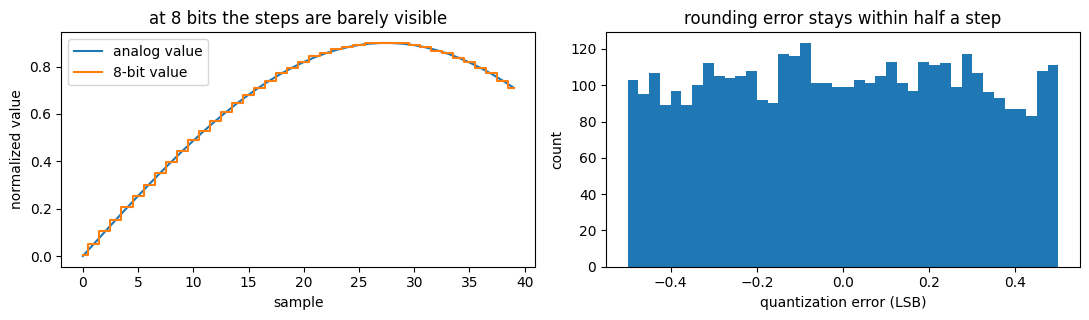

  lsb_normalized                   0.00784314
  error_rms_measured               0.0022356
  error_rms_theory_lsb_over_sqrt12 0.00226412
  sqnr_measured_db                 49.0911
  sqnr_ideal_full_scale_db         49.92


In [4]:
# Stage 3 -- 8-bit quantization and binary codes. Needs the Stage 0 cell.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def quantize_to_uint8(normalized: np.ndarray) -> np.ndarray:
    '''Map the range -1 .. +1 onto integer codes 0 .. 255 (values outside are clipped).'''
    scaled = np.round((normalized + 1.0) / 2.0 * 255.0)
    return np.clip(scaled, 0, 255).astype(np.uint8)


def dequantize_from_uint8(codes: np.ndarray) -> np.ndarray:
    '''The calibration: turn codes 0 .. 255 back into values -1 .. +1.'''
    return codes.astype(float) / 255.0 * 2.0 - 1.0


def to_binary_string(code: int, n_bits: int) -> str:
    '''Write an integer in binary by repeatedly dividing by two.'''
    if code < 0 or code >= 2**n_bits:
        raise ValueError(f"{code} does not fit in {n_bits} bits")
    bits, remaining = "", code
    while len(bits) < n_bits:
        bits = str(remaining % 2) + bits      # the remainder is the next bit, from the right
        remaining = remaining // 2
    return bits


def describe_code(code: int) -> str:
    '''Say whether a code is inside the ADC range or sitting on a rail.'''
    if code == 0:
        return "bottom rail (signal may be clipped)"
    elif code == 255:
        return "top rail (signal may be clipped)"
    else:
        return "in range"


def run_binary(results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Quantize a sine to 8 bits, print some codes in binary, and measure the rounding error.'''
    n_samples = 1024 if phone_mode else 4096
    sample_index = np.arange(n_samples)
    normalized = 0.9 * np.sin(2 * np.pi * 37.3 * sample_index / n_samples)
    codes = quantize_to_uint8(normalized)
    error = dequantize_from_uint8(codes) - normalized
    lsb = 2.0 / 255.0                                   # one step, in normalized units

    print(" sample   value   code   binary     note")
    for i in range(0, 60, 12):                          # a few selected samples
        code = int(codes[i])
        assert to_binary_string(code, 8) == format(code, "08b")
        print(f" {i:5d}  {normalized[i]:+.4f}   {code:3d}   {to_binary_string(code, 8)}   {describe_code(code)}")

    try:
        to_binary_string(300, 8)                        # 300 needs 9 bits
    except ValueError as problem:
        print("\ncaught an error on purpose:", problem)

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
    axes[0].plot(sample_index[:40], normalized[:40], label="analog value")
    axes[0].step(sample_index[:40], dequantize_from_uint8(codes[:40]), where="mid", label="8-bit value")
    axes[0].set_xlabel("sample"); axes[0].set_ylabel("normalized value"); axes[0].legend()
    axes[0].set_title("at 8 bits the steps are barely visible")
    axes[1].hist(error / lsb, bins=40)
    axes[1].set_xlabel("quantization error (LSB)"); axes[1].set_ylabel("count")
    axes[1].set_title("rounding error stays within half a step")
    fig.tight_layout()

    signal_rms = float(np.sqrt(np.mean(normalized**2)))
    error_rms = float(np.sqrt(np.mean(error**2)))
    summary = {
        "lsb_normalized": lsb,
        "error_rms_measured": error_rms,
        "error_rms_theory_lsb_over_sqrt12": lsb / np.sqrt(12),
        "sqnr_measured_db": float(20 * np.log10(signal_rms / error_rms)),
        "sqnr_ideal_full_scale_db": 6.02 * 8 + 1.76,
    }
    save_outputs(fig, summary, results_dir, "binary", filename)
    finish_figure(fig, show)
    return summary


stage3 = run_binary(results_dir=Path("results"), phone_mode=False, filename="stage3_binary.png", show=True)
print_summary(stage3)
assert abs(stage3["error_rms_measured"] / stage3["error_rms_theory_lsb_over_sqrt12"] - 1) < 0.15

The measured SQNR is about 1 dB below the ideal full-scale figure
because the sine only reaches 0.9 of full scale
($20\log_{10}0.9 = -0.9$ dB).

**In engineering language**

- *We measured* nothing new: the input is the simulated value on a −1 to +1 scale.
- *We estimated* the quantization noise as the RMS difference between
  the 8-bit and the original values.
- *We validated* it against the textbook model $\text{LSB}/\sqrt{12}$,
  which assumes the rounding error is uniformly spread over one step.

**Exercises**

1. Write 200 in 8-bit binary.
2. An 8-bit ADC spans 2 V. Roughly how big is one step?
3. What is the ideal SQNR of a 12-bit ADC?

<details><summary>Solutions</summary>

1. $200 = 128 + 64 + 8$, so `11001000`.
2. $2\ \text{V}/255 \approx 7.8$ mV.
3. $6.02 \times 12 + 1.76 = 74.0$ dB.

</details>

# Stage 4 — SymPy symbolic physics

**In plain English.** NumPy works with numbers; SymPy works with
*formulas*. It can differentiate, integrate and take limits exactly.

For $s(t) = A\cos(2\pi f t + \phi)$:

- the **derivative** $ds/dt$ is how fast the voltage is changing (V/s);
- the **integral** over one full period is zero — the wave spends as
  much time above zero as below;
- the **mean of $s^2$** over a period is $A^2/2$, which is where the
  "signal power" of Stage 1 came from.

## Limits, and when l'Hôpital's rule is allowed

l'Hôpital's rule says $\lim f/g = \lim f'/g'$ — **but only when the
original limit has the form $0/0$ or $\infty/\infty$.** Three cases:

1. $\displaystyle\lim_{x\to1}\frac{x^2-1}{x-1}$ is $0/0$. It is a
   *removable* hole: factor the top, cancel, get $x + 1 \to 2$. Algebra
   is simpler than l'Hôpital and shows *why* the limit exists.
2. $\displaystyle\lim_{x\to0}\frac{\sin x}{x} = 1$ is also $0/0$. (It
   matters here because the spectrum of a rectangular window is this
   function — the leakage skirt of Stage 2.) l'Hôpital gives the right
   number, but using it as a *proof* is circular: the derivative of
   $\sin x$ is itself derived from this limit.
3. $\displaystyle\lim_{x\to0}\frac{\cos x}{1+x}$ is $1/1$, **not**
   indeterminate. Differentiating top and bottom anyway gives
   $-\sin x/1 \to 0$, which is simply wrong. The true limit is 1.

So the habit to build is: **check the form first.** The function below
refuses to apply the rule when the form is not indeterminate.

s(t)        =
A⋅cos(2⋅π⋅f⋅t + φ)

ds/dt       =
-2⋅π⋅A⋅f⋅sin(2⋅π⋅f⋅t + φ)

integral    =
A⋅sin(2⋅π⋅f⋅t + φ)
──────────────────
      2⋅π⋅f       

integral over one period = 0
mean of s^2 over one period = A**2/2

(x^2-1)/(x-1): form 0/0 | cancels to x + 1 | limit 2
sin(x)/x:      form 0/0 | limit 1 | l'Hopital also gives 1
cos(x)/(1+x):  form determinate | true limit 1 | blind l'Hopital would give 0 (wrong)
   the checked version refuses: l'Hopital's rule does not apply: the form is not 0/0 or inf/inf


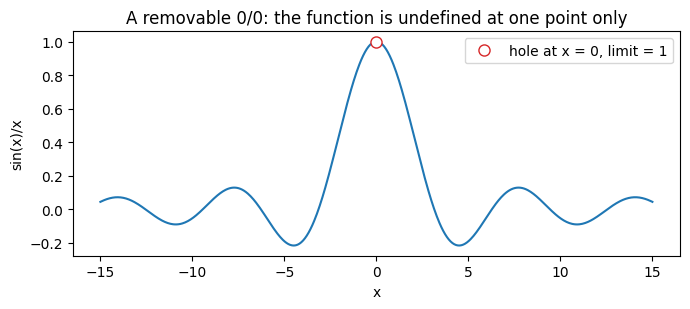

  integral_over_one_period         0
  mean_square_over_A_squared       0.5
  removable_limit                  2
  sinc_limit                       1
  cos_over_1_plus_x_true_limit     1
  cos_over_1_plus_x_blind_lhopital 0


In [5]:
# Stage 4 -- symbolic derivative, integral and limits. Needs the Stage 0 cell.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp


def limit_form(numerator: sp.Expr, denominator: sp.Expr, variable: sp.Symbol, point: sp.Expr) -> str:
    '''Classify a quotient at a point as "0/0", "inf/inf" or "determinate".'''
    top = sp.limit(numerator, variable, point)
    bottom = sp.limit(denominator, variable, point)
    if top == 0 and bottom == 0:
        return "0/0"
    elif top in (sp.oo, -sp.oo) and bottom in (sp.oo, -sp.oo):
        return "inf/inf"
    else:
        return "determinate"


def lhopital_step(numerator: sp.Expr, denominator: sp.Expr, variable: sp.Symbol, point: sp.Expr) -> sp.Expr:
    '''Apply l'Hopital's rule once -- but only if the form really is indeterminate.'''
    form = limit_form(numerator, denominator, variable, point)
    if form == "determinate":
        raise ValueError("l'Hopital's rule does not apply: the form is not 0/0 or inf/inf")
    return sp.limit(sp.diff(numerator, variable) / sp.diff(denominator, variable), variable, point)


def run_symbolic(results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Differentiate and integrate s(t), then work three limits.'''
    sp.init_printing()                                   # nicer formula output
    t, A, f = sp.symbols("t A f", positive=True)
    phi, x = sp.symbols("phi x", real=True)
    s = A * sp.cos(2 * sp.pi * f * t + phi)

    print("s(t)        ="); sp.pprint(s)
    print("\nds/dt       ="); sp.pprint(sp.diff(s, t))
    print("\nintegral    ="); sp.pprint(sp.integrate(s, t))
    over_one_period = sp.simplify(sp.integrate(s, (t, 0, 1 / f)))
    mean_square = sp.simplify(f * sp.integrate(s**2, (t, 0, 1 / f)))
    print("\nintegral over one period =", over_one_period)
    print("mean of s^2 over one period =", mean_square)

    # 1. removable 0/0: algebra first
    removable = (x**2 - 1) / (x - 1)
    print("\n(x^2-1)/(x-1): form", limit_form(x**2 - 1, x - 1, x, 1),
          "| cancels to", sp.cancel(removable), "| limit", sp.limit(removable, x, 1))
    # 2. sin(x)/x: a genuine 0/0
    sinc_limit = sp.limit(sp.sin(x) / x, x, 0)
    print("sin(x)/x:      form", limit_form(sp.sin(x), x, x, 0), "| limit", sinc_limit,
          "| l'Hopital also gives", lhopital_step(sp.sin(x), x, x, 0))
    # 3. not indeterminate: the rule must not be used
    true_limit = sp.limit(sp.cos(x) / (1 + x), x, 0)
    blind = sp.limit(sp.diff(sp.cos(x), x) / sp.diff(1 + x, x), x, 0)
    print("cos(x)/(1+x):  form", limit_form(sp.cos(x), 1 + x, x, 0),
          "| true limit", true_limit, "| blind l'Hopital would give", blind, "(wrong)")
    try:
        lhopital_step(sp.cos(x), 1 + x, x, 0)
    except ValueError as problem:
        print("   the checked version refuses:", problem)

    xs = np.linspace(-15, 15, 600)                       # 600 points: none lands exactly on 0
    sinc_numeric = sp.lambdify(x, sp.sin(x) / x, "numpy")
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.plot(xs, sinc_numeric(xs))
    ax.plot(0, 1, "o", mfc="white", mec="C3", ms=8, label="hole at x = 0, limit = 1")
    ax.set_xlabel("x"); ax.set_ylabel("sin(x)/x"); ax.legend()
    ax.set_title("A removable 0/0: the function is undefined at one point only")
    fig.tight_layout()

    summary = {
        "integral_over_one_period": float(over_one_period),
        "mean_square_over_A_squared": float(mean_square / A**2),
        "removable_limit": float(sp.limit(removable, x, 1)),
        "sinc_limit": float(sinc_limit),
        "cos_over_1_plus_x_true_limit": float(true_limit),
        "cos_over_1_plus_x_blind_lhopital": float(blind),
    }
    save_outputs(fig, summary, results_dir, "symbolic", filename)
    finish_figure(fig, show)
    return summary


stage4 = run_symbolic(results_dir=Path("results"), phone_mode=False, filename="stage4_symbolic.png", show=True)
print_summary(stage4)
assert stage4["mean_square_over_A_squared"] == 0.5 and stage4["sinc_limit"] == 1.0

**In engineering language**

- *We derived* (not measured) $ds/dt$, $\int s\,dt$ and the mean square exactly.
- *We validated* the mean square $A^2/2$ against Stage 1, where the
  simulated RMS matched $\sqrt{A^2/2 + \sigma^2}$.
- A symbolic result is exact *for the model*. It says nothing about
  whether the model describes a real detector.

**Exercises**

1. For $A = 1$ V and $f = 5$ MHz, what is the largest value of $|ds/dt|$?
2. Find $\lim_{x\to0}(1-\cos x)/x^2$. Is l'Hôpital allowed?
3. Is l'Hôpital allowed for $\lim_{x\to0}(x+1)/(x+2)$? What is the limit?

<details><summary>Solutions</summary>

1. $ds/dt = -2\pi f A\sin(\dots)$, so the maximum is $2\pi f A = 3.14\times10^{7}$ V/s.
2. The form is $0/0$, so yes. Applying it twice: $\sin x/(2x) \to \cos x/2 \to 1/2$.
3. No: the form is $1/2$, which is the answer. Differentiating top and
   bottom would give $1/1 = 1$, which is wrong.

</details>

# Stage 5 — A differentiable optical model

**In plain English.** A focused laser spot is brightest in the middle
and fades smoothly, roughly as a Gaussian:

$$I(x) = I_0 \exp\!\left(-\frac{(x - x_0)^2}{2w^2}\right)$$

| Symbol | Meaning | Unit |
|---|---|---|
| $x_0$ | centre position | µm |
| $w$ | width (standard deviation); full width at half maximum is $2.355\,w$ | µm |
| $I_0$ | peak intensity | arbitrary units |

Given noisy measurements, we want the three numbers that best explain
them. **Gradient descent** does this by trial and improvement: compute
how wrong the model is (the *loss*), ask which way each parameter
should move to reduce it (the *gradient*), take a small step, repeat.
PyTorch computes the gradients automatically.

**A gradient is an optimization tool, not a physical law.** It tells
you how the *mismatch* changes when you nudge a parameter of *your
model*. It would point just as confidently toward the best fit of a
wrong model.

**Worked example.** True spot: $x_0 = 2.0$ µm, $w = 1.5$ µm,
$I_0 = 1.0$, noise 0.05. Starting guess: $x_0 = 0$, $w = 3$, $I_0 = 0.5$.

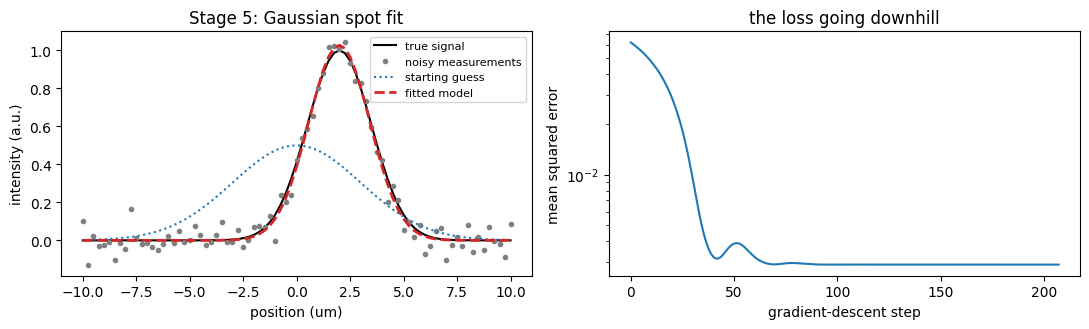

  center_um_fitted                 1.99531
  center_um_true                   2
  center_um_sigma                  0.0309211
  width_um_fitted                  1.43011
  width_um_true                    1.5
  width_um_sigma                   0.0309211
  amplitude_fitted                 1.02706
  amplitude_true                   1
  amplitude_sigma                  0.0192315
  steps_used                       208
  final_loss                       0.0028841
  noise_variance                   0.0025
  max_difference_from_scipy_fit    5.64201e-05


In [6]:
# Stage 5 -- fit a Gaussian spot by gradient descent in PyTorch. Needs the Stage 0 cell.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.optimize import curve_fit


class GaussianSpot(torch.nn.Module):
    '''A 1-D Gaussian intensity profile whose three parameters can be adjusted by gradients.'''

    def __init__(self, center_um: float, width_um: float, amplitude: float) -> None:
        super().__init__()
        self.center_um = torch.nn.Parameter(torch.tensor(center_um, dtype=torch.float64))
        self.width_um = torch.nn.Parameter(torch.tensor(width_um, dtype=torch.float64))
        self.amplitude = torch.nn.Parameter(torch.tensor(amplitude, dtype=torch.float64))

    def forward(self, x_um: torch.Tensor) -> torch.Tensor:
        '''I(x) = I0 exp(-(x - x0)^2 / (2 w^2))'''
        return self.amplitude * torch.exp(-(x_um - self.center_um) ** 2 / (2 * self.width_um ** 2))


def gaussian_profile(x_um: np.ndarray, center_um: float, width_um: float, amplitude: float) -> np.ndarray:
    '''The same Gaussian in plain NumPy, for the reference fit.'''
    return amplitude * np.exp(-(x_um - center_um) ** 2 / (2 * width_um ** 2))


def make_spot_data(x_um: np.ndarray, center_um: float, width_um: float, amplitude: float,
                   noise_std: float, seed: int) -> np.ndarray:
    '''Noisy measurements of a Gaussian spot with known ("true") parameters.'''
    rng = np.random.default_rng(seed)
    clean = amplitude * np.exp(-(x_um - center_um) ** 2 / (2 * width_um ** 2))
    return clean + rng.normal(0.0, noise_std, size=x_um.shape)


def fit_spot(model: GaussianSpot, x_um: torch.Tensor, measured: torch.Tensor,
             learning_rate: float, max_steps: int, tolerance: float) -> list[float]:
    '''Gradient descent: stop when the loss stops improving or the step budget runs out.'''
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    losses: list[float] = []
    step = 0
    while step < max_steps:
        optimizer.zero_grad()
        loss = torch.mean((model(x_um) - measured) ** 2)   # mean squared mismatch
        loss.backward()                                    # gradients of the loss
        optimizer.step()                                   # move each parameter downhill
        losses.append(float(loss.detach()))
        if step > 20 and abs(losses[-2] - losses[-1]) < tolerance:
            break
        step += 1
    return losses


def parameter_uncertainty(model: GaussianSpot, x_um: torch.Tensor, noise_std: float) -> np.ndarray:
    '''One-sigma uncertainty of (centre, width, amplitude) from the fit's sensitivity matrix.

    If J holds the derivative of every predicted point with respect to every parameter,
    the parameter covariance for independent noise sigma is sigma^2 (J^T J)^-1.
    '''
    def predict(parameters: torch.Tensor) -> torch.Tensor:
        return parameters[2] * torch.exp(-(x_um - parameters[0]) ** 2 / (2 * parameters[1] ** 2))

    fitted = torch.stack([model.center_um.detach(), model.width_um.detach(), model.amplitude.detach()])
    jacobian = torch.autograd.functional.jacobian(predict, fitted)
    covariance = noise_std ** 2 * torch.linalg.inv(jacobian.T @ jacobian)
    return torch.sqrt(torch.diag(covariance)).numpy()


def run_fit(results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Fit the spot model to synthetic data and compare with the known truth.'''
    true_center, true_width, true_amplitude, noise_std = 2.0, 1.5, 1.0, 0.05
    n_points = 41 if phone_mode else 81
    max_steps = 300 if phone_mode else 600
    x_np = np.linspace(-10.0, 10.0, n_points)
    y_np = make_spot_data(x_np, true_center, true_width, true_amplitude, noise_std, seed=3)
    x_um, measured = torch.tensor(x_np), torch.tensor(y_np)

    model = GaussianSpot(center_um=0.0, width_um=3.0, amplitude=0.5)
    with torch.no_grad():
        initial_guess = model(x_um).numpy()
    losses = fit_spot(model, x_um, measured, learning_rate=0.05, max_steps=max_steps, tolerance=1e-12)
    sigma = parameter_uncertainty(model, x_um, noise_std)
    with torch.no_grad():
        fitted_curve = model(x_um).numpy()
    # reference method: SciPy's standard least-squares fit of the same model to the same data
    reference, _ = curve_fit(gaussian_profile, x_np, y_np, p0=[0.0, 3.0, 0.5])
    ours = np.array([float(model.center_um.detach()), abs(float(model.width_um.detach())),
                     float(model.amplitude.detach())])

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].plot(x_np, true_amplitude * np.exp(-(x_np - true_center) ** 2 / (2 * true_width ** 2)),
                 "k-", label="true signal")
    axes[0].plot(x_np, y_np, ".", color="0.5", label="noisy measurements")
    axes[0].plot(x_np, initial_guess, ":", label="starting guess")
    axes[0].plot(x_np, fitted_curve, "C3--", lw=2, label="fitted model")
    axes[0].set_xlabel("position (um)"); axes[0].set_ylabel("intensity (a.u.)")
    axes[0].set_title("Stage 5: Gaussian spot fit"); axes[0].legend(fontsize=8)
    axes[1].semilogy(losses)
    axes[1].set_xlabel("gradient-descent step"); axes[1].set_ylabel("mean squared error")
    axes[1].set_title("the loss going downhill")
    fig.tight_layout()

    summary = {
        "center_um_fitted": float(model.center_um.detach()), "center_um_true": true_center,
        "center_um_sigma": float(sigma[0]),
        "width_um_fitted": abs(float(model.width_um.detach())), "width_um_true": true_width,
        "width_um_sigma": float(sigma[1]),
        "amplitude_fitted": float(model.amplitude.detach()), "amplitude_true": true_amplitude,
        "amplitude_sigma": float(sigma[2]),
        "steps_used": float(len(losses)), "final_loss": losses[-1], "noise_variance": noise_std ** 2,
        "max_difference_from_scipy_fit": float(np.max(np.abs(ours - np.abs(reference)))),
    }
    save_outputs(fig, summary, results_dir, "fit", filename)
    finish_figure(fig, show)
    return summary


stage5 = run_fit(results_dir=Path("results"), phone_mode=False, filename="stage5_fit.png", show=True)
print_summary(stage5)
for name in ("center_um", "width_um"):
    assert abs(stage5[name + "_fitted"] - stage5[name + "_true"]) < 0.15
assert abs(stage5["amplitude_fitted"] - stage5["amplitude_true"]) < 0.15
assert stage5["max_difference_from_scipy_fit"] < 1e-3

Two checks worth reading off the summary: each fitted value lands
within a few of its own one-sigma uncertainties of the truth, and the
final loss is close to the noise variance (0.0025) — the model has
explained everything except the noise, which is the best a fit can do.

**In engineering language**

- *We measured* (simulated) intensity at 81 positions spaced 0.25 µm apart.
- *We estimated* centre, width and amplitude by least squares, using
  Adam gradient descent, assuming a Gaussian shape and independent
  noise of known size.
- *We validated* two ways: against the simulation's true values, and
  against a reference method (SciPy's least-squares fit of the same
  model), which agrees to better than 0.001.
- *The model predicts* the spot profile; it does not *prove* the real
  beam is Gaussian. A real beam with a different shape would still
  return three confident-looking numbers.

**Exercises**

1. What happens if the learning rate is far too large?
2. What is the full width at half maximum of a spot with $w = 1.5$ µm?
3. How does the parameter uncertainty change if the noise doubles? If you take four times as many points?

<details><summary>Solutions</summary>

1. Each step overshoots the minimum; the loss oscillates or grows instead of settling.
2. $2.355 \times 1.5 = 3.53$ µm.
3. Doubling the noise doubles the uncertainty. Four times as many
   points (over the same range) halves it, since it scales as $1/\sqrt{N}$.

</details>

# Stage 6 — A brain-imaging abstraction

> **Visualization only.** Everything in this stage is invented by the
> code below. It is not a scan of anyone, it cannot diagnose anything,
> and it does not reveal thoughts. The point is to practise handling
> multi-dimensional data with uncertainty.

**In plain English.** Imaging data is rarely just a picture. Optical
brain-imaging methods, for instance, record how much light comes back
at each **place**, at each **time**, at more than one **wavelength**,
and every number has an **uncertainty**. That is naturally a
four-dimensional array:

`intensity[time, wavelength, y, x]`, with a matching `uncertainty` array.

Here a head-shaped outline contains three made-up regions (A, B, C).
Each region "activates" once — a smooth rise and fall — at a different
time. Averaging the pixels in a region reduces the noise: the standard
error of a mean of $n$ independent pixels is $\sigma/\sqrt{n}$.

**Worked example.** A 32 × 32 map, 41 time frames over 16 s, two
wavelengths (760 and 850 nm, with an arbitrary simulated response of
1.0 and 0.6).

intensity array shape (time, wavelength, y, x): (41, 2, 32, 32)


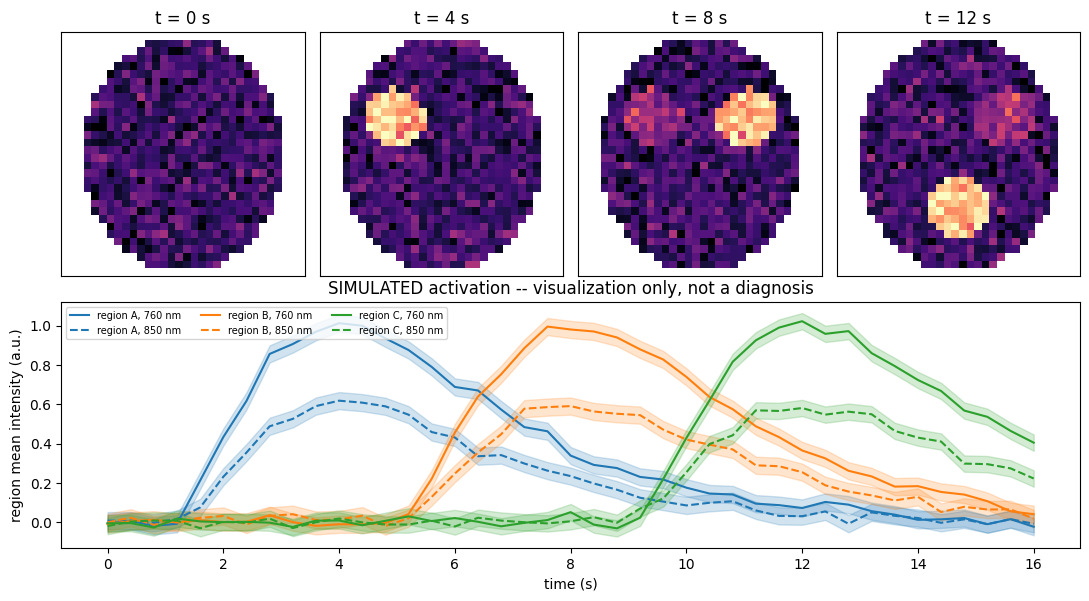

  region_A_peak_time_s             4
  region_A_standard_error          0.0218797
  region_B_peak_time_s             7.6
  region_B_standard_error          0.0218797
  region_C_peak_time_s             12
  region_C_standard_error          0.0208013


In [7]:
# Stage 6 -- a simulated activation map with time, wavelength and uncertainty. Needs the Stage 0 cell.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def make_region_map(grid_size: int) -> tuple[np.ndarray, np.ndarray]:
    '''Return (head_mask, region_labels). Labels: 0 = no region, 1/2/3 = regions A/B/C.'''
    y, x = np.mgrid[-1:1:grid_size * 1j, -1:1:grid_size * 1j]
    head_mask = (x / 0.85) ** 2 + y ** 2 <= 1.0              # an ellipse standing in for a head outline
    region_labels = np.zeros((grid_size, grid_size), dtype=int)
    centers = [(-0.4, -0.3), (0.4, -0.3), (0.0, 0.45)]       # invented positions, not anatomy
    for index, (center_x, center_y) in enumerate(centers):
        inside = (x - center_x) ** 2 + (y - center_y) ** 2 <= 0.25 ** 2
        region_labels[inside & head_mask] = index + 1
    return head_mask, region_labels


def activation_time_course(time_s: np.ndarray, onset_s: float, rise_s: float) -> np.ndarray:
    '''A smooth bump that starts at the onset and peaks (at height 1) two rise-times later.'''
    elapsed = np.clip(time_s - onset_s, 0.0, None) / rise_s
    return elapsed ** 2 * np.exp(-elapsed) / (4 * np.exp(-2.0))


def simulate_cube(time_s: np.ndarray, wavelength_response: list[float], onsets_s: list[float],
                  region_labels: np.ndarray, noise_std: float, seed: int) -> dict[str, np.ndarray]:
    '''Build intensity[time, wavelength, y, x] and a matching uncertainty array.'''
    rng = np.random.default_rng(seed)
    shape = (time_s.size, len(wavelength_response)) + region_labels.shape
    intensity = np.zeros(shape)
    for w_index, response in enumerate(wavelength_response):
        for region, onset_s in enumerate(onsets_s, start=1):
            course = activation_time_course(time_s, onset_s, rise_s=1.5)
            intensity[:, w_index, region_labels == region] += response * course[:, None]
    intensity += rng.normal(0.0, noise_std, size=shape)
    return {"intensity": intensity, "uncertainty": np.full(shape, noise_std)}


def region_mean(cube: dict[str, np.ndarray], region_labels: np.ndarray, region: int,
                w_index: int) -> tuple[np.ndarray, np.ndarray]:
    '''Mean over a region's pixels at each time, and its standard error sigma/sqrt(n).'''
    pixels = region_labels == region
    mean = cube["intensity"][:, w_index, pixels].mean(axis=1)
    standard_error = cube["uncertainty"][:, w_index, pixels].mean(axis=1) / np.sqrt(pixels.sum())
    return mean, standard_error


def run_brain_map(results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Simulate the data cube, show four frames, and plot each region's time course.'''
    grid_size = 16 if phone_mode else 32
    time_s = np.linspace(0.0, 16.0, 21 if phone_mode else 41)
    axes_info = {"wavelength_nm": [760.0, 850.0], "response": [1.0, 0.6], "onsets_s": [1.0, 5.0, 9.0]}
    head_mask, region_labels = make_region_map(grid_size)
    cube = simulate_cube(time_s, axes_info["response"], axes_info["onsets_s"], region_labels,
                         noise_std=0.15, seed=4)
    print("intensity array shape (time, wavelength, y, x):", cube["intensity"].shape)

    fig = plt.figure(figsize=(11, 6))
    grid = fig.add_gridspec(2, 4)
    for column, frame_time in enumerate([0.0, 4.0, 8.0, 12.0]):
        frame = int(np.argmin(np.abs(time_s - frame_time)))
        ax = fig.add_subplot(grid[0, column])
        image = np.where(head_mask, cube["intensity"][frame, 0], np.nan)   # blank outside the outline
        ax.imshow(image, vmin=-0.3, vmax=1.2, cmap="magma")
        ax.set_title(f"t = {time_s[frame]:.0f} s"); ax.set_xticks([]); ax.set_yticks([])
    ax = fig.add_subplot(grid[1, :])
    summary: dict[str, float] = {}
    for region, name in enumerate(["A", "B", "C"], start=1):
        for w_index, style in enumerate(["-", "--"]):
            mean, error = region_mean(cube, region_labels, region, w_index)
            ax.plot(time_s, mean, style, color=f"C{region - 1}",
                    label=f"region {name}, {axes_info['wavelength_nm'][w_index]:.0f} nm")
            ax.fill_between(time_s, mean - 2 * error, mean + 2 * error, color=f"C{region - 1}", alpha=0.2)
        mean, error = region_mean(cube, region_labels, region, 0)
        summary[f"region_{name}_peak_time_s"] = float(time_s[int(np.argmax(mean))])
        summary[f"region_{name}_standard_error"] = float(error[0])
    ax.set_xlabel("time (s)"); ax.set_ylabel("region mean intensity (a.u.)")
    ax.set_title("SIMULATED activation -- visualization only, not a diagnosis")
    ax.legend(ncol=3, fontsize=7)
    fig.tight_layout()

    save_outputs(fig, summary, results_dir, "brain_map", filename)
    finish_figure(fig, show)
    return summary


stage6 = run_brain_map(results_dir=Path("results"), phone_mode=False, filename="stage6_brain_map.png", show=True)
print_summary(stage6)
for name, expected_peak in [("A", 4.0), ("B", 8.0), ("C", 12.0)]:
    assert abs(stage6[f"region_{name}_peak_time_s"] - expected_peak) <= 0.8

**In engineering language**

- *We simulated* intensity in arbitrary units on a 32 × 32 grid, at 41
  times and 2 wavelengths, with a stated per-pixel uncertainty of 0.15.
- *We estimated* each region's activity as the mean over its pixels,
  with standard error $\sigma/\sqrt{n}$, assuming independent pixel noise.
- *We validated* that each region's peak falls at onset + 3 s, as built in.
- **Limits:** the regions, timings and wavelength responses are
  invented. Nothing here can be interpreted about a real person.

**Exercises**

1. How many numbers are in a cube with 41 times, 2 wavelengths and a 32 × 32 grid?
2. Per-pixel noise is 0.15. What is the standard error of the mean over 100 independent pixels?
3. Give two reasons this map could not be used to diagnose anyone.

<details><summary>Solutions</summary>

1. $41 \times 2 \times 32 \times 32 = 83{,}968$.
2. $0.15/\sqrt{100} = 0.015$.
3. Any two of: the data is invented, not measured; there is no
   calibration to a physical quantity; no reference population or
   clinical validation; the "regions" are not anatomy; a picture that
   looks like a scan carries no medical information by itself.

</details>

# Stage 7 — Interpretable features and a decision tree

**In plain English.** Picture small particles flowing one at a time
through a laser spot. Each one produces a short pulse on the detector.
Instead of feeding the raw pulse to a black box, we first compute a few
numbers a person can understand:

| Feature | How it is computed | Unit |
|---|---|---|
| peak intensity | largest value above the baseline | V |
| centroid | intensity-weighted average time | µs |
| width | intensity-weighted spread in time | µs |
| dominant frequency | tallest FFT peak above 100 kHz (the RF tag) | kHz |
| SNR | peak ÷ baseline noise, in dB | dB |
| estimated velocity | spot width ÷ pulse width | m/s |

A **decision tree** then learns a short list of yes/no questions on
those features. A **random forest** averages many small trees.

The three particle types are **synthetic labels**: type A is dimmer
and slower; types B and C look the same except for their tag frequency.

**A classifier is not proof of a mechanism.** The tree will report
which features separate the labels *in this dataset*. Here we know why
— we wrote the simulator. With real data, a feature can separate two
groups because of the instrument, the day, or the way samples were
prepared, and the tree would use it just as happily.

training events: 168   test events: 72
decision tree accuracy: 0.944   random forest accuracy: 1.000

random forest confusion matrix (rows = true A, B, C; columns = predicted):
[[24  0  0]
 [ 0 24  0]
 [ 0  0 24]]

the tree's rules:
|--- dominant_khz <= 250.00
|   |--- velocity_m_s <= 1.59
|   |   |--- peak_v <= 1.14
|   |   |   |--- class: A
|   |   |--- peak_v >  1.14
|   |   |   |--- class: B
|   |--- velocity_m_s >  1.59
|   |   |--- class: B
|--- dominant_khz >  250.00
|   |--- class: C



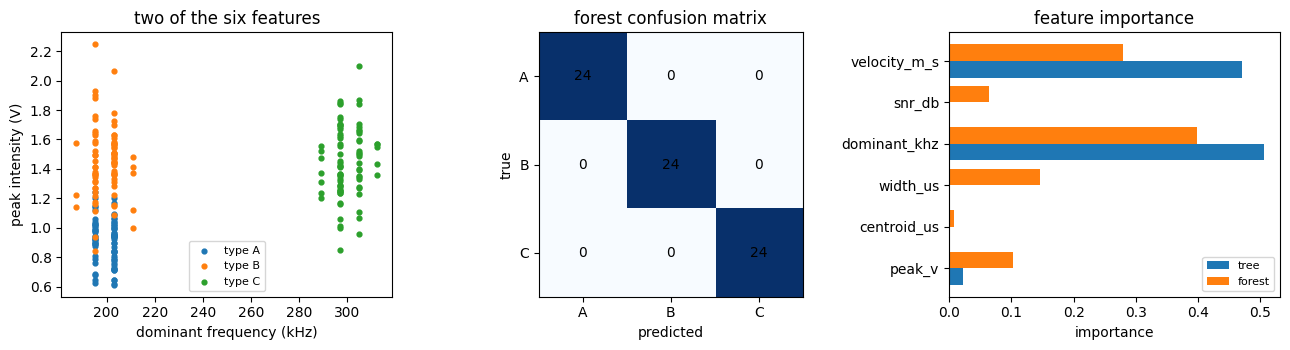

  n_train                          168
  n_test                           72
  tree_accuracy                    0.944444
  forest_accuracy                  1
  velocity_estimate_over_truth_median 1.27373
  forest_importance_peak_v         0.102508
  forest_importance_centroid_us    0.00882793
  forest_importance_width_us       0.146323
  forest_importance_dominant_khz   0.398465
  forest_importance_snr_db         0.0646391
  forest_importance_velocity_m_s   0.279237


In [8]:
# Stage 7 -- features, a decision tree and a small random forest. Needs the Stage 0 cell.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text


def simulate_event(time_s: np.ndarray, amplitude_v: float, velocity_m_s: float, tag_frequency_hz: float,
                   center_s: float, spot_width_m: float, noise_std_v: float,
                   rng: np.random.Generator) -> np.ndarray:
    '''One particle crossing a Gaussian spot: a Gaussian pulse carrying an RF-tag ripple, plus noise.'''
    transit_s = spot_width_m / velocity_m_s                 # faster particle -> shorter pulse
    envelope = amplitude_v * np.exp(-(time_s - center_s) ** 2 / (2 * transit_s ** 2))
    ripple = 1.0 + 0.5 * np.cos(2 * np.pi * tag_frequency_hz * time_s)
    return envelope * ripple + rng.normal(0.0, noise_std_v, size=time_s.shape)


def extract_features(time_s: np.ndarray, signal_v: np.ndarray, sample_rate_hz: float,
                     spot_width_m: float) -> dict[str, float]:
    '''Reduce one pulse to six interpretable numbers.'''
    baseline_v = float(np.mean(signal_v[:20]))              # the first samples contain no particle
    noise_v = float(np.std(signal_v[:20]))
    corrected = signal_v - baseline_v
    peak_v = float(corrected.max())
    weights = np.where(corrected > 0.2 * peak_v, corrected, 0.0)   # ignore the noisy tails
    centroid_s = float(np.sum(weights * time_s) / np.sum(weights))
    width_s = float(np.sqrt(np.sum(weights * (time_s - centroid_s) ** 2) / np.sum(weights)))
    freqs_hz = np.fft.rfftfreq(signal_v.size, d=1 / sample_rate_hz)
    spectrum = np.abs(np.fft.rfft(corrected))
    spectrum[freqs_hz < 100e3] = 0.0                        # skip the pulse envelope near DC
    return {
        "peak_v": peak_v,
        "centroid_us": centroid_s * 1e6,
        "width_us": width_s * 1e6,
        "dominant_khz": float(freqs_hz[int(np.argmax(spectrum))] / 1e3),
        "snr_db": float(20 * np.log10(peak_v / noise_v)),
        "velocity_m_s": spot_width_m / width_s,
    }


def build_dataset(n_per_class: int, seed: int) -> pd.DataFrame:
    '''Simulate events for three synthetic particle types and tabulate their features.'''
    rng = np.random.default_rng(seed)
    sample_rate_hz, spot_width_m, noise_std_v = 2e6, 10e-6, 0.05
    time_s = np.arange(256) / sample_rate_hz
    particle_types = [
        {"label": "A", "amplitude_v": 0.6, "velocity_m_s": 1.0, "tag_hz": 200e3},
        {"label": "B", "amplitude_v": 1.0, "velocity_m_s": 1.5, "tag_hz": 200e3},
        {"label": "C", "amplitude_v": 1.0, "velocity_m_s": 1.5, "tag_hz": 300e3},
    ]
    rows = []
    for particle in particle_types:
        for _ in range(n_per_class):
            amplitude_v = particle["amplitude_v"] * (1 + 0.15 * rng.normal())
            velocity_m_s = particle["velocity_m_s"] * (1 + 0.12 * rng.normal())
            center_s = 64e-6 + 4e-6 * rng.normal()
            signal_v = simulate_event(time_s, amplitude_v, velocity_m_s, particle["tag_hz"], center_s,
                                      spot_width_m, noise_std_v, rng)
            row = extract_features(time_s, signal_v, sample_rate_hz, spot_width_m)
            row["true_velocity_m_s"] = velocity_m_s
            row["label"] = particle["label"]
            rows.append(row)
    return pd.DataFrame(rows)


def run_classify(results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Build the feature table, save and reload it, train two classifiers, and report.'''
    feature_names = ["peak_v", "centroid_us", "width_us", "dominant_khz", "snr_db", "velocity_m_s"]
    table = build_dataset(n_per_class=30 if phone_mode else 80, seed=5)

    plot_path = resolve_output_path(results_dir, "classify", ".png", filename)
    csv_path = plot_path.with_suffix(".csv")
    table.to_csv(csv_path, index=False)                      # file output ...
    try:
        table = pd.read_csv(csv_path)                        # ... and file input
    except FileNotFoundError as problem:
        raise RuntimeError(f"could not read back {csv_path}") from problem

    train, test = train_test_split(table, test_size=0.3, random_state=5, stratify=table["label"])
    tree = DecisionTreeClassifier(max_depth=3, random_state=5).fit(train[feature_names], train["label"])
    forest = RandomForestClassifier(n_estimators=25, max_depth=4, random_state=5).fit(
        train[feature_names], train["label"])
    tree_accuracy = accuracy_score(test["label"], tree.predict(test[feature_names]))
    forest_accuracy = accuracy_score(test["label"], forest.predict(test[feature_names]))
    matrix = confusion_matrix(test["label"], forest.predict(test[feature_names]), labels=["A", "B", "C"])

    print(f"training events: {len(train)}   test events: {len(test)}")
    print(f"decision tree accuracy: {tree_accuracy:.3f}   random forest accuracy: {forest_accuracy:.3f}")
    print("\nrandom forest confusion matrix (rows = true A, B, C; columns = predicted):")
    print(matrix)
    print("\nthe tree's rules:")
    print(export_text(tree, feature_names=feature_names))

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for index, label in enumerate(["A", "B", "C"]):
        group = table[table["label"] == label]
        axes[0].scatter(group["dominant_khz"], group["peak_v"], s=12, color=f"C{index}", label=f"type {label}")
    axes[0].set_xlabel("dominant frequency (kHz)"); axes[0].set_ylabel("peak intensity (V)")
    axes[0].set_title("two of the six features"); axes[0].legend(fontsize=8)
    axes[1].imshow(matrix, cmap="Blues")
    for row in range(3):
        for column in range(3):
            axes[1].text(column, row, str(matrix[row, column]), ha="center", va="center")
    axes[1].set_xticks(range(3), ["A", "B", "C"]); axes[1].set_yticks(range(3), ["A", "B", "C"])
    axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true"); axes[1].set_title("forest confusion matrix")
    positions = np.arange(len(feature_names))
    axes[2].barh(positions - 0.2, tree.feature_importances_, height=0.4, label="tree")
    axes[2].barh(positions + 0.2, forest.feature_importances_, height=0.4, label="forest")
    axes[2].set_yticks(positions, feature_names); axes[2].set_xlabel("importance")
    axes[2].set_title("feature importance"); axes[2].legend(fontsize=8)
    fig.tight_layout()

    summary = {
        "n_train": float(len(train)), "n_test": float(len(test)),
        "tree_accuracy": float(tree_accuracy), "forest_accuracy": float(forest_accuracy),
        "velocity_estimate_over_truth_median": float(np.median(table["velocity_m_s"] / table["true_velocity_m_s"])),
    }
    for name, importance in zip(feature_names, forest.feature_importances_):
        summary[f"forest_importance_{name}"] = float(importance)
    fig.savefig(plot_path, dpi=110, bbox_inches="tight")
    plot_path.with_suffix(".json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    finish_figure(fig, show)
    return summary


stage7 = run_classify(results_dir=Path("results"), phone_mode=False, filename="stage7_classify.png", show=True)
print_summary(stage7)
assert stage7["forest_accuracy"] > 0.8

**Two honest observations from the output.**

- `velocity_estimate_over_truth_median` is not 1. The width feature
  ignores the pulse tails, so it under-reads the true width and the
  velocity estimate comes out too high by a steady factor. It still
  separates the types, but it would need calibrating before being
  quoted as a speed. *An estimate is only as good as its assumptions.*
- `centroid_us` has almost no importance. That is correct: arrival
  time was random for every type. If some quirk of data collection had
  made one type arrive later, the tree would have used it — and been
  right for the wrong reason.

**In engineering language**

- *We simulated* detector voltage at 2 MS/s for 240 single-particle events.
- *We estimated* six features per event with the stated algorithms.
- *We validated* the classifiers on a held-out 30 % test set and the
  velocity estimate against the simulated true velocity.
- *The model predicts* the label from the features. It does not show
  that the features *cause* the label.

**Exercises**

1. A pulse has width 5 µs in a 10 µm spot. Estimate the velocity.
2. A confusion matrix reads `[[18,0,0],[1,16,1],[0,2,16]]`. What is the accuracy?
3. Dominant frequency has the highest importance. Does that prove particle type determines tag frequency?

<details><summary>Solutions</summary>

1. $v = 10\ \mu\text{m} / 5\ \mu\text{s} = 2$ m/s.
2. Correct = $18 + 16 + 16 = 50$ of 54, so 92.6 %.
3. No. In this simulation we *assigned* the tag frequency to the type.
   Importance measures usefulness for prediction in this dataset, not cause.

</details>

# The automation controller

One function, `run_command`, maps a command word to a stage using a
plain `if / elif / else` chain. `run_pipeline` runs several commands in
a row and keeps going if one fails. `main` reads command-line style
arguments.

| Command | Stage |
|---|---|
| `simulate` | 1 |
| `fft` | 2 |
| `binary` | 3 |
| `symbolic` | 4 |
| `fit` | 5 |
| `brain_map` | 6 |
| `classify` | 7 |
| `all` | every stage in order (not allowed in phone mode) |

Options: `--phone` (smaller, one experiment at a time),
`--results-dir NAME`, `--filename NAME.png` (explicit name; otherwise
the next free numbered name is used), `--no-show`.

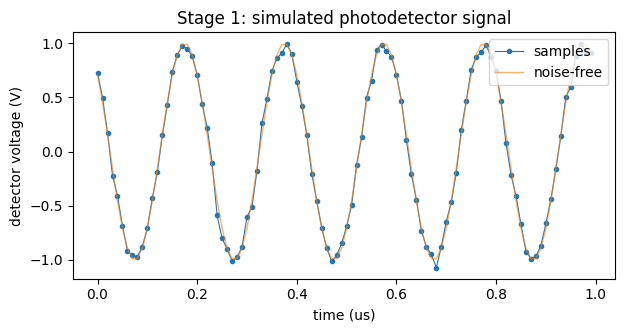

simulate summary:
  n_samples                        100
  snr_db                           23.0103
  rms_measured_v                   0.702198
  rms_expected_v                   0.708872


In [9]:
# Controller -- needs every stage cell above to have been run.
import argparse
import sys
from pathlib import Path

COMMANDS = ["simulate", "fft", "binary", "symbolic", "fit", "brain_map", "classify"]


def run_command(command: str, results_dir: Path, phone_mode: bool, filename: str, show: bool) -> dict[str, float]:
    '''Run exactly one experiment, chosen by name.'''
    if command == "simulate":
        return run_simulate(results_dir, phone_mode, filename, show)
    elif command == "fft":
        return run_fft(results_dir, phone_mode, filename, show)
    elif command == "binary":
        return run_binary(results_dir, phone_mode, filename, show)
    elif command == "symbolic":
        return run_symbolic(results_dir, phone_mode, filename, show)
    elif command == "fit":
        return run_fit(results_dir, phone_mode, filename, show)
    elif command == "brain_map":
        return run_brain_map(results_dir, phone_mode, filename, show)
    elif command == "classify":
        return run_classify(results_dir, phone_mode, filename, show)
    else:
        raise ValueError(f"unknown command {command!r}; choose one of {COMMANDS}")


def run_pipeline(commands: list[str], results_dir: Path, phone_mode: bool,
                 show: bool) -> dict[str, dict[str, float]]:
    '''Run several experiments in order. Outputs get automatic numbered names.'''
    if phone_mode and len(commands) > 1:
        raise ValueError("phone mode runs one experiment at a time; pick a single command")
    summaries: dict[str, dict[str, float]] = {}
    for command in commands:
        try:
            summaries[command] = run_command(command, results_dir, phone_mode, "", show)
            print(f"[done]   {command}")
        except (ValueError, OSError, RuntimeError) as problem:
            print(f"[failed] {command}: {problem}")           # report and carry on with the rest
    return summaries


def main(argv: list[str]) -> int:
    '''Command-line entry point. Returns 0 on success and 2 on a usage problem.'''
    parser = argparse.ArgumentParser(description="Physics-Informed Optical Science Automation")
    parser.add_argument("command", choices=COMMANDS + ["all"])
    parser.add_argument("--phone", action="store_true", help="small, one experiment at a time")
    parser.add_argument("--results-dir", default="results")
    parser.add_argument("--filename", default="", help="explicit output name, e.g. my_run.png")
    parser.add_argument("--no-show", action="store_true", help="save the plot without displaying it")
    options = parser.parse_args(argv)
    results_dir, show = Path(options.results_dir), not options.no_show
    try:
        if options.command == "all":
            run_pipeline(COMMANDS, results_dir, options.phone, show)
        else:
            summary = run_command(options.command, results_dir, options.phone, options.filename, show)
            print(f"{options.command} summary:")
            print_summary(summary)
    except ValueError as problem:
        print("cannot run:", problem)
        return 2
    return 0


if __name__ == "__main__":
    if "ipykernel" in sys.modules:
        # inside a notebook: run one small experiment as a demonstration
        main(["simulate", "--phone", "--filename", "controller_demo.png"])
    else:
        sys.exit(main(sys.argv[1:]))

## The controller in use

The next cell runs the whole pipeline into a temporary folder (so the
demonstration leaves nothing behind), lists the automatically numbered
files it produced, runs one stage a second time to show that nothing is
overwritten, and then shows the two refusals: `all` in phone mode, and
an unknown command.

In [10]:
# Controller demonstration -- needs the controller cell.
import tempfile
from pathlib import Path

import pandas as pd

with tempfile.TemporaryDirectory() as temporary_name:
    temporary_dir = Path(temporary_name)
    summaries = run_pipeline(COMMANDS, temporary_dir, phone_mode=False, show=False)
    run_command("fft", temporary_dir, phone_mode=True, filename="", show=False)    # a second fft run
    print("\nfiles written:")
    for path in sorted(temporary_dir.iterdir()):
        print("  ", path.name)
    assert (temporary_dir / "fft_001.png").exists() and (temporary_dir / "fft_002.png").exists()

print("\nphone mode with 'all':")
main(["all", "--phone", "--no-show"])

print("\nunknown command:")
try:
    run_command("teleport", Path("results"), phone_mode=True, filename="", show=False)
except ValueError as problem:
    print("  ", problem)

headline = {"simulate": "snr_db", "fft": "max_brightness_error", "binary": "sqnr_measured_db",
            "symbolic": "sinc_limit", "fit": "center_um_fitted", "brain_map": "region_A_peak_time_s",
            "classify": "forest_accuracy"}
pd.DataFrame([{"command": command, "headline quantity": key, "value": round(summaries[command][key], 4)}
              for command, key in headline.items()])

[done]   simulate


[done]   fft
 sample   value   code   binary     note
     0  +0.0000   128   10000000   in range
    12  +0.5705   200   11001000   in range
    24  +0.8825   240   11110000   in range
    36  +0.7945   229   11100101   in range
    48  +0.3465   172   10101100   in range

caught an error on purpose: 300 does not fit in 8 bits


[done]   binary
s(t)        =
A⋅cos(2⋅π⋅f⋅t + φ)

ds/dt       =
-2⋅π⋅A⋅f⋅sin(2⋅π⋅f⋅t + φ)

integral    =
A⋅sin(2⋅π⋅f⋅t + φ)
──────────────────
      2⋅π⋅f       

integral over one period = 0
mean of s^2 over one period = A**2/2

(x^2-1)/(x-1): form 0/0 | cancels to x + 1 | limit 2
sin(x)/x:      form 0/0 | limit 1 | l'Hopital also gives 1
cos(x)/(1+x):  form determinate | true limit 1 | blind l'Hopital would give 0 (wrong)
   the checked version refuses: l'Hopital's rule does not apply: the form is not 0/0 or inf/inf
[done]   symbolic


[done]   fit
intensity array shape (time, wavelength, y, x): (41, 2, 32, 32)
[done]   brain_map
training events: 168   test events: 72
decision tree accuracy: 0.944   random forest accuracy: 1.000

random forest confusion matrix (rows = true A, B, C; columns = predicted):
[[24  0  0]
 [ 0 24  0]
 [ 0  0 24]]

the tree's rules:
|--- dominant_khz <= 250.00
|   |--- velocity_m_s <= 1.59
|   |   |--- peak_v <= 1.14
|   |   |   |--- class: A
|   |   |--- peak_v >  1.14
|   |   |   |--- class: B
|   |--- velocity_m_s >  1.59
|   |   |--- class: B
|--- dominant_khz >  250.00
|   |--- class: C



[done]   classify

files written:
   binary_001.json
   binary_001.png
   brain_map_001.json
   brain_map_001.png
   classify_001.csv
   classify_001.json
   classify_001.png
   fft_001.json
   fft_001.png
   fft_002.json
   fft_002.png
   fit_001.json
   fit_001.png
   simulate_001.json
   simulate_001.png
   symbolic_001.json
   symbolic_001.png

phone mode with 'all':
cannot run: phone mode runs one experiment at a time; pick a single command

unknown command:
   unknown command 'teleport'; choose one of ['simulate', 'fft', 'binary', 'symbolic', 'fit', 'brain_map', 'classify']


,command,headline quantity,value
0,simulate,snr_db,23.0103
1,fft,max_brightness_error,0.0070
2,binary,sqnr_measured_db,49.0911
3,symbolic,sinc_limit,1.0000
4,fit,center_um_fitted,1.9953
5,brain_map,region_A_peak_time_s,4.0000
6,classify,forest_accuracy,1.0000


# Where these ideas appear in published research

The stages above are toy versions of ideas described in the open
scientific literature, including work from Bahram Jalali's group at
UCLA. This section explains the connection conceptually. **This
notebook does not use, reproduce or have access to any of that group's
equipment or data.**

**Light can carry information in several ways:** in *time* (when a
pulse arrives), *frequency* (how fast the intensity flickers),
*wavelength* (colour), *intensity* (brightness) or *phase* (where the
wave is in its cycle). Stage 1's $A$, $f$ and $\phi$ are three of those.

**Photonic time-stretch** addresses a practical bottleneck: some optical
events are too fast for an electronic digitizer. In a dispersive medium
different wavelengths travel at different speeds, so a short broadband
pulse spreads out — its spectrum is laid out along the time axis, and
the result is slow enough to digitize. Conceptually it is a *mapping
from a fast optical event onto a slower electronic time axis*. The
duration after stretching is roughly

$$\Delta t \approx |D|\,L\,\Delta\lambda$$

with $D$ the fibre's dispersion, $L$ its length and $\Delta\lambda$ the
optical bandwidth.

**RF-tagged fluorescence** is an example of *encoding* for high-speed
detection: each point of a sample is made to fluoresce with its own
radio-frequency beat, so one fast detector records all the points at
once and a Fourier transform separates them — exactly the Stage 2
worked example.

**Physics-inspired image processing** borrows the mathematics of
optical propagation (for instance, a frequency-dependent phase) as a
numerical filter for finding edges and textures in ordinary images.

The measurement chain this notebook imitates:

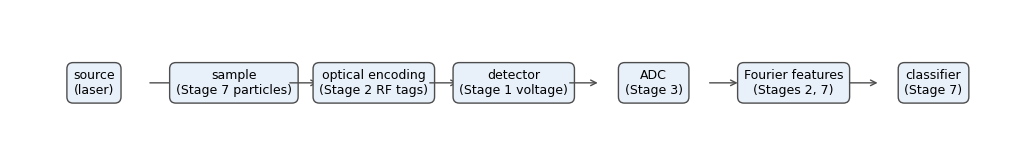

a 10 nm wide pulse through 10 km of such fibre spreads to about 1.7 ns


In [11]:
# Block diagram of the measurement chain, and a time-stretch estimate. Needs the Stage 0 cell.
import matplotlib.pyplot as plt
from matplotlib.figure import Figure


def draw_block_diagram(blocks: list[tuple[str, str]]) -> Figure:
    '''Draw labelled boxes left to right; each box names a block and the stage that imitates it.'''
    fig, ax = plt.subplots(figsize=(13, 1.9))
    for index, (name, stage) in enumerate(blocks):
        ax.text(index, 0.0, f"{name}\n{stage}", ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#e8f0fa", edgecolor="0.3"))
        if index < len(blocks) - 1:
            ax.annotate("", xy=(index + 0.62, 0.0), xytext=(index + 0.38, 0.0),
                        arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.set_xlim(-0.6, len(blocks) - 0.4); ax.set_ylim(-1, 1); ax.axis("off")
    return fig


def stretched_duration_s(dispersion_ps_per_nm_km: float, fiber_length_km: float, bandwidth_nm: float) -> float:
    '''Delta t = |D| L Delta lambda, converted from picoseconds to seconds.'''
    return abs(dispersion_ps_per_nm_km) * fiber_length_km * bandwidth_nm * 1e-12


chain = [("source", "(laser)"), ("sample", "(Stage 7 particles)"), ("optical encoding", "(Stage 2 RF tags)"),
         ("detector", "(Stage 1 voltage)"), ("ADC", "(Stage 3)"), ("Fourier features", "(Stages 2, 7)"),
         ("classifier", "(Stage 7)")]
diagram = draw_block_diagram(chain)
plt.show(); plt.close(diagram)

# illustrative numbers: ordinary telecom fibre near 1550 nm has D of about 17 ps/(nm km)
duration = stretched_duration_s(dispersion_ps_per_nm_km=17.0, fiber_length_km=10.0, bandwidth_nm=10.0)
print(f"a 10 nm wide pulse through 10 km of such fibre spreads to about {duration * 1e9:.1f} ns")
assert abs(duration - 1.7e-9) < 1e-12

# Uncertainty and error budget

An **error budget** lists every source of error, puts a number on each
in the same units, and combines them. Independent errors add as a
root-sum-of-squares, so the largest term dominates — which tells you
where improvement effort is worth spending.

For the Stage 1–3 detector chain ($\sigma = 0.05$ V noise, 200 samples
at 100 MS/s, 8-bit ADC spanning 2 V):

In [12]:
# Error budget for the detector chain. Self-contained.
import numpy as np
import pandas as pd


def build_error_budget(noise_std_v: float, n_samples: int, sample_rate_hz: float,
                       adc_bits: int, full_scale_v: float) -> pd.DataFrame:
    '''Tabulate the main error sources for one sampled-sinusoid measurement.'''
    lsb_v = full_scale_v / (2 ** adc_bits - 1)
    quantization_v = lsb_v / np.sqrt(12)
    per_sample_v = float(np.sqrt(noise_std_v ** 2 + quantization_v ** 2))
    rows = [
        {"source": "detector noise, per sample", "value": noise_std_v, "unit": "V",
         "note": "set in the simulation"},
        {"source": "ADC quantization, per sample", "value": quantization_v, "unit": "V",
         "note": "LSB / sqrt(12)"},
        {"source": "combined, per sample", "value": per_sample_v, "unit": "V",
         "note": "root-sum-of-squares"},
        {"source": "amplitude estimate from N samples", "value": per_sample_v * np.sqrt(2 / n_samples),
         "unit": "V", "note": "sigma * sqrt(2/N)"},
        {"source": "frequency resolution", "value": sample_rate_hz / n_samples, "unit": "Hz",
         "note": "fs / N"},
    ]
    return pd.DataFrame(rows)


budget = build_error_budget(noise_std_v=0.05, n_samples=200, sample_rate_hz=100e6, adc_bits=8, full_scale_v=2.0)
budget["value"] = budget["value"].map(lambda number: f"{number:.3g}")
budget

,source,value,unit,note
0,"detector noise, per sample",0.05,V,set in the simulation
1,"ADC quantization, per sample",0.00226,V,LSB / sqrt(12)
2,"combined, per sample",0.0501,V,root-sum-of-squares
3,amplitude estimate from N samples,0.00501,V,sigma * sqrt(2/N)
4,frequency resolution,5e+05,Hz,fs / N


**Reading it.** Detector noise (50 mV) is about twenty times larger
than quantization (2.3 mV), so a better ADC would change nothing;
averaging more samples or reducing noise would.

**Not in the table**, because the simulation contains none of it, but
present in any real system: calibration error, drift, timing jitter,
nonlinearity, and **model error** — the signal not actually being a
clean cosine or the spot not actually being Gaussian. Statistical
uncertainty shrinks with more data; model error does not.

## Four phrases, used precisely

| Phrase | What it commits you to |
|---|---|
| "We **measured** …" | name the sensor quantity and its units |
| "We **estimated** …" | name the algorithm and its assumptions |
| "We **validated** …" | name what it was compared against: known simulated truth, or a reference method |
| "The model **predicts** …" | a statement about the model. It is not "the system proves" |

# Study schedule: 25-minute sessions

Each session is one focused block that can be finished, or abandoned
and restarted, without losing the thread. Take a 5-minute break between
sessions. In phone mode, run the single command shown.

| Session | Do this | Command |
|---|---|---|
| 1 | Read the scope and Stage 0; run it; change one variable's type | — |
| 2 | Stage 1: read the equation table, run the cell | `simulate` |
| 3 | Stage 1 exercises; change $A$, $f$, $\sigma$ and predict the SNR first | `simulate` |
| 4 | Stage 2: read the four-quantity table, run the cell | `fft` |
| 5 | Stage 2 exercises; move a tag off its bin and watch it leak | `fft` |
| 6 | Stage 3: run, convert three numbers to binary by hand | `binary` |
| 7 | Stage 3 exercises; change 8 bits to 4 and look at the steps | `binary` |
| 8 | Stage 4: derivative and integral | `symbolic` |
| 9 | Stage 4: the three limits; do the exercises on paper | `symbolic` |
| 10 | Stage 5: read the model, run the fit | `fit` |
| 11 | Stage 5 exercises; try a learning rate ten times larger | `fit` |
| 12 | Stage 6: run, read the array shape aloud dimension by dimension | `brain_map` |
| 13 | Stage 7: read the feature table, run the cell | `classify` |
| 14 | Stage 7: read the printed tree rules; do the exercises | `classify` |
| 15 | Controller: run `all`, then read the error budget | `all` |
| 16 | Fill in the report template for one stage of your choice | — |

# Final project rubric

Pick one stage, change something meaningful about it (a parameter, a
noise level, a model), and write it up with the report template below.

| Criterion | 4 — Excellent | 2 — Developing | 0 — Missing |
|---|---|---|---|
| **Correctness** | results match known truth within stated uncertainty; checks are asserted | results plausible but unchecked | results wrong or absent |
| **Units** | every quantity has a unit in text, tables and axis labels | some units missing | no units |
| **Plots** | labelled axes with units, legend, title, readable at phone size | plot present but unlabelled | no plot |
| **Reproducibility** | fixed seeds; runs top to bottom; outputs saved to `results/` | runs, but results change between runs | does not run |
| **Uncertainty** | error sources listed and quantified; limits of interpretation stated | uncertainty mentioned without numbers | none |
| **Code quality** | small functions, type hints, docstrings, explicit parameters, no hidden state | works but long or uncommented | unreadable |

Total: 24 points.

# Report template

```text
Research question
    One sentence: what are you trying to find out?

Physical model
    The equation(s) and what each term represents.

Coordinate system
    What are the axes (time, position, frequency)? Where is zero?

Variables and units
    A table: symbol, meaning, unit, value or range.

Measurement or simulation method
    What was measured or simulated, with what sampling and what noise?

Fourier or statistical method
    Which algorithm, and which assumptions does it rely on?

Results
    The numbers and plots, with units.

Error and uncertainty
    Each error source, its size, and the combined uncertainty.

Limits of interpretation
    What the result does NOT show. "The model predicts" vs "the system proves".

Next engineering step
    The one change that would most improve the result, and why.
```